<a href="https://colab.research.google.com/github/Ayushi-Sharma19/DIP/blob/main/Misc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RGB to HSI Conversion

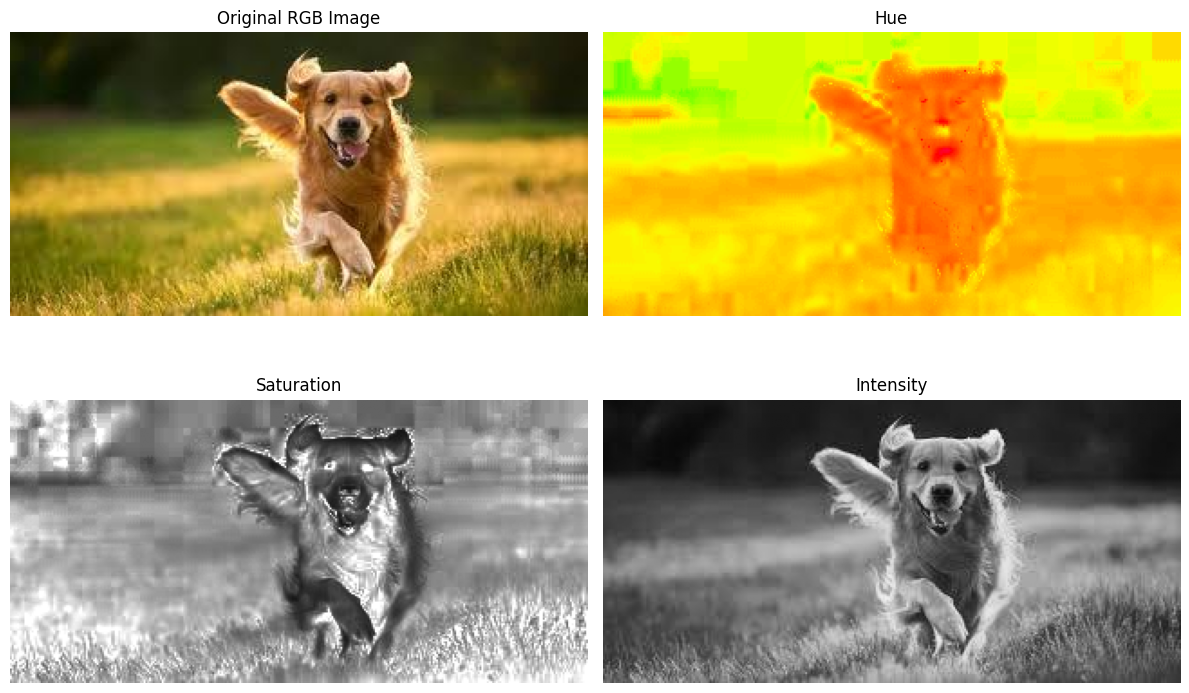

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read RGB image
img = cv2.imread('image.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Normalize RGB values
rgb = img.astype(float) / 255.0

R = rgb[:, :, 0]
G = rgb[:, :, 1]
B = rgb[:, :, 2]

# Calculate Intensity
I = (R + G + B) / 3

# Calculate Saturation
minimum = np.minimum(np.minimum(R, G), B)

S = 1 - (3 * minimum / (R + G + B + 1e-10))

# Calculate Hue
numerator = 0.5 * ((R - G) + (R - B))

denominator = np.sqrt(
    (R - G)**2 + (R - B)*(G - B)
)

theta = np.arccos(
    np.clip(numerator / (denominator + 1e-10), -1, 1)
)

H = np.where(B <= G, theta, 2*np.pi - theta)

H = np.degrees(H)

# Set hue to zero for grayscale pixels
H[S < 1e-10] = 0

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img)
plt.title('Original RGB Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(H, cmap='hsv', vmin=0, vmax=360)
plt.title('Hue')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(S, cmap='gray', vmin=0, vmax=1)
plt.title('Saturation')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(I, cmap='gray', vmin=0, vmax=1)
plt.title('Intensity')
plt.axis('off')

plt.tight_layout()
plt.show()

HSI to RGB Conversion

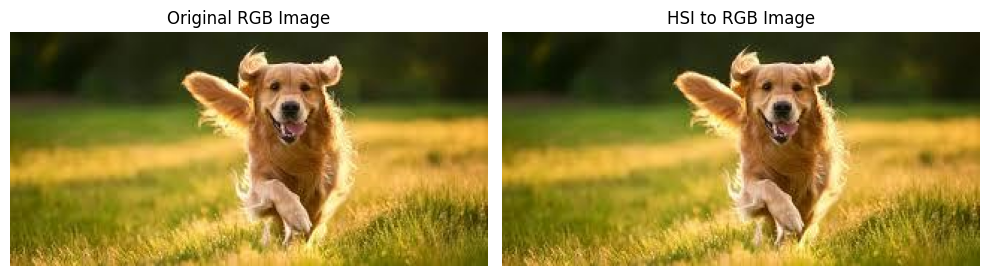

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read RGB image
img = cv2.imread('image.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Normalize RGB values
rgb = img.astype(float) / 255.0

R = rgb[:, :, 0]
G = rgb[:, :, 1]
B = rgb[:, :, 2]

# RGB to HSI conversion
I = (R + G + B) / 3

total = R + G + B
minimum = np.minimum(np.minimum(R, G), B)

S = np.where(total > 1e-10,
             1 - (3 * minimum / (total + 1e-10)), 0)

num = 0.5 * ((R - G) + (R - B))
den = np.sqrt((R-G)**2 + (R-B)*(G-B))

theta = np.arccos(np.clip(
    num / (den + 1e-10), -1, 1
))

H = np.where(B <= G, theta, 2*np.pi - theta)
H = np.degrees(H)
H[S < 1e-10] = 0

# HSI to RGB conversion
H = H % 360

R_new = np.zeros_like(H)
G_new = np.zeros_like(H)
B_new = np.zeros_like(H)

# Sector 1: 0 to 120 degrees
m1 = (H < 120)

h = np.radians(H[m1])

B_new[m1] = I[m1] * (1 - S[m1])

R_new[m1] = I[m1] * (
    1 + S[m1] * np.cos(h) /
    np.cos(np.radians(60) - h)
)

G_new[m1] = 3*I[m1] - R_new[m1] - B_new[m1]

# Sector 2: 120 to 240 degrees
m2 = (H >= 120) & (H < 240)

h = np.radians(H[m2] - 120)

R_new[m2] = I[m2] * (1 - S[m2])

G_new[m2] = I[m2] * (
    1 + S[m2] * np.cos(h) /
    np.cos(np.radians(60) - h)
)

B_new[m2] = 3*I[m2] - R_new[m2] - G_new[m2]

# Sector 3: 240 to 360 degrees
m3 = (H >= 240)

h = np.radians(H[m3] - 240)

G_new[m3] = I[m3] * (1 - S[m3])

B_new[m3] = I[m3] * (
    1 + S[m3] * np.cos(h) /
    np.cos(np.radians(60) - h)
)

R_new[m3] = 3*I[m3] - G_new[m3] - B_new[m3]

# Combine RGB channels
rgb_new = np.stack(
    [R_new, G_new, B_new], axis=2
)

# Convert to 8-bit image
rgb_new = np.clip(rgb_new * 255, 0, 255).astype(np.uint8)

# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original RGB Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(rgb_new)
plt.title('HSI to RGB Image')
plt.axis('off')

plt.tight_layout()
plt.show()

Huffman Coding and Decoding

In [11]:
import heapq
from collections import Counter

# Input message
text = input("Enter a string: ")

# Calculate frequency of characters
freq = Counter(text)

# Create priority queue
heap = []
counter = 0

for char, frequency in freq.items():
    heapq.heappush(
        heap, (frequency, counter, char)
    )
    counter += 1

# Build Huffman tree
while len(heap) > 1:

    f1, _, left = heapq.heappop(heap)
    f2, _, right = heapq.heappop(heap)

    node = (left, right)

    heapq.heappush(
        heap, (f1 + f2, counter, node)
    )
    counter += 1

root = heap[0][2]

# Generate Huffman codes
codes = {}

def generate_codes(node, code=""):

    if isinstance(node, str):
        codes[node] = code if code else "0"
        return

    left, right = node

    generate_codes(left, code + "0")
    generate_codes(right, code + "1")

generate_codes(root)

# Encode message
encoded = ""

for char in text:
    encoded += codes[char]

# Decode message
decoded = ""
node = root

for bit in encoded:

    if bit == '0':
        node = node[0]
    else:
        node = node[1]

    if isinstance(node, str):
        decoded += node
        node = root

# Display results
print("\nCharacter Frequencies:")
for char, frequency in freq.items():
    print(repr(char), ":", frequency)

print("\nHuffman Codes:")
for char, code in codes.items():
    print(repr(char), ":", code)

print("\nOriginal Message:", text)
print("Encoded Message:", encoded)
print("Decoded Message:", decoded)

Enter a string: BANANA

Character Frequencies:
'B' : 1
'A' : 3
'N' : 2

Huffman Codes:
'A' : 0
'B' : 10
'N' : 11

Original Message: BANANA
Encoded Message: 100110110
Decoded Message: BANANA


Arithmetic Coding and Decoding

In [12]:
from fractions import Fraction
from collections import Counter

# Input message
text = input("Enter a string: ")

if not text:
    print("Please enter a non-empty string.")

else:
    # Calculate character frequencies
    freq = Counter(text)

    # Calculate probabilities
    total = len(text)
    symbols = sorted(freq.keys())

    probabilities = {
        ch: Fraction(freq[ch], total)
        for ch in symbols
    }

    # Calculate cumulative probabilities
    cumulative = {}
    low = Fraction(0)

    for ch in symbols:
        high = low + probabilities[ch]
        cumulative[ch] = (low, high)
        low = high

    # Arithmetic encoding
    low = Fraction(0)
    high = Fraction(1)

    for ch in text:

        width = high - low

        char_low, char_high = cumulative[ch]

        high = low + width * char_high
        low = low + width * char_low

    # Encoded value
    encoded = (low + high) / 2

    # Arithmetic decoding
    value = encoded
    decoded = ""

    low = Fraction(0)
    high = Fraction(1)

    for i in range(len(text)):

        width = high - low

        scaled = (value - low) / width

        for ch in symbols:

            char_low, char_high = cumulative[ch]

            if char_low <= scaled < char_high:

                decoded += ch

                high = low + width * char_high
                low = low + width * char_low

                break

    # Display results
    print("\nCharacter Frequencies:")
    for ch, f in freq.items():
        print(repr(ch), ":", f)

    print("\nProbabilities:")
    for ch, p in probabilities.items():
        print(repr(ch), ":", p)

    print("\nOriginal Message:", text)
    print("Final Interval:", float(low), "to", float(high))
    print("Encoded Value:", encoded)
    print("Decoded Message:", decoded)

Enter a string: BANANA

Character Frequencies:
'B' : 1
'A' : 3
'N' : 2

Probabilities:
'A' : 1/2
'B' : 1/6
'N' : 1/3

Original Message: BANANA
Final Interval: 0.5648148148148148 to 0.5671296296296297
Encoded Value: 163/288
Decoded Message: BANANA
